# Load Dataset

In [41]:
import pandas as pd
df = pd.read_csv("IMDB Dataset.csv")
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [42]:
df.columns

Index(['review', 'sentiment'], dtype='object')

In [43]:
df.shape

(50000, 2)

In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


In [45]:
df.isnull().sum()

review       0
sentiment    0
dtype: int64

In [46]:
df['sentiment']

0        positive
1        positive
2        positive
3        negative
4        positive
           ...   
49995    positive
49996    negative
49997    negative
49998    negative
49999    negative
Name: sentiment, Length: 50000, dtype: object

In [47]:
df['sentiment'].value_counts()

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

In [48]:
df['review']

0        One of the other reviewers has mentioned that ...
1        A wonderful little production. <br /><br />The...
2        I thought this was a wonderful way to spend ti...
3        Basically there's a family where a little boy ...
4        Petter Mattei's "Love in the Time of Money" is...
                               ...                        
49995    I thought this movie did a down right good job...
49996    Bad plot, bad dialogue, bad acting, idiotic di...
49997    I am a Catholic taught in parochial elementary...
49998    I'm going to have to disagree with the previou...
49999    No one expects the Star Trek movies to be high...
Name: review, Length: 50000, dtype: object

In [49]:
df['review'].value_counts()

review
Loved today's show!!! It was a variety and not solely cooking (which would have been great too). Very stimulating and captivating, always keeping the viewer peeking around the corner to see what was coming up next. She is as down to earth and as personable as you get, like one of us which made the show all the more enjoyable. Special guests, who are friends as well made for a nice surprise too. Loved the 'first' theme and that the audience was invited to play along too. I must admit I was shocked to see her come in under her time limits on a few things, but she did it and by golly I'll be writing those recipes down. Saving time in the kitchen means more time with family. Those who haven't tuned in yet, find out what channel and the time, I assure you that you won't be disappointed.                                                                                                                                                                                                         

In [50]:
x = df["review"]
x.head()

0    One of the other reviewers has mentioned that ...
1    A wonderful little production. <br /><br />The...
2    I thought this was a wonderful way to spend ti...
3    Basically there's a family where a little boy ...
4    Petter Mattei's "Love in the Time of Money" is...
Name: review, dtype: object

In [51]:
y = df["sentiment"]
y.head()

0    positive
1    positive
2    positive
3    negative
4    positive
Name: sentiment, dtype: object

# Convert Positive/Negative into Numbers

In [52]:
from sklearn.preprocessing import LabelEncoder

In [53]:
encoder = LabelEncoder()
encoder

LabelEncoder()

In [54]:
y = encoder.fit_transform(y)
y[:10]

array([1, 1, 1, 0, 1, 1, 1, 0, 0, 1])

In [55]:
print(encoder.classes_)

['negative' 'positive']


In [56]:
for i, label in enumerate(encoder.classes_):
    print(label, ":", i)

negative : 0
positive : 1


# Train/Test Split

In [57]:
from sklearn.model_selection import train_test_split

In [58]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [59]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(40000,)
(10000,)
(40000,)
(10000,)


# Text Cleaning

In [60]:
import re

In [61]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    return text

In [62]:
x_train = x_train.apply(clean_text)
x_test = x_test.apply(clean_text)

In [63]:
x_train.iloc[:5]

47808    i caught this little gem totally by accident b...
20154    i cant believe that i let myself into this mov...
43069    spoiler alert it just gets to me the nerve som...
19413    if theres one thing ive learnt from watching g...
13673    i remember when this was in theaters reviews s...
Name: review, dtype: object

# Bag of Words

In [64]:
from sklearn.feature_extraction.text import CountVectorizer

In [65]:
vectorizer = CountVectorizer()
vectorizer

,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,None
,stop_words,None
,token_pattern,'(?u)\\b\\w\\w+\\b'
,ngram_range,"(1, ...)"
,analyzer,'word'


In [66]:
x_train_bow = vectorizer.fit_transform(x_train)

In [67]:
x_test_bow = vectorizer.transform(x_test)

In [68]:
print(x_train_bow.shape)
print(x_test_bow.shape)

(40000, 154996)
(10000, 154996)


In [69]:
print(vectorizer.get_feature_names_out()[:50])

['aa' 'aaa' 'aaaaaaaargh' 'aaaaaaahhhhhhggg' 'aaaaagh' 'aaaaah' 'aaaaargh'
 'aaaaarrrrrrgggggghhhhhh' 'aaaahhhhhh' 'aaaahhhhhhh' 'aaaand' 'aaaarrgh'
 'aaaggghhhhhhh' 'aaagh' 'aaah' 'aaahhhhhhh' 'aaall' 'aaand' 'aaargh'
 'aaarrrghim' 'aab' 'aachen' 'aada' 'aag' 'aage' 'aagh' 'aaghh' 'aah'
 'aahed' 'aahemy' 'aahhh' 'aahhhh' 'aahing' 'aaila' 'aailiyah' 'aaip'
 'aaja' 'aajala' 'aak' 'aakash' 'aake' 'aaker' 'aalcc' 'aaliyah'
 'aaliyahs' 'aalox' 'aames' 'aamesbr' 'aamess' 'aamir']


# Machine Learning Model

In [70]:
from sklearn.naive_bayes import MultinomialNB

In [71]:
model = MultinomialNB()
model

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [72]:
model.fit(x_train_bow, y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


# Prediction

In [73]:
y_pred = model.predict(x_test_bow)

print(y_pred[:10])

[0 1 1 0 0 0 0 0 0 0]


# Actual vs Predicted

In [74]:
result = pd.DataFrame({
    "actual": y_test,
    "predicted": y_pred
})
print(result.head(20))

    actual  predicted
0        0          0
1        0          1
2        1          1
3        0          0
4        0          0
5        0          0
6        0          0
7        0          0
8        0          0
9        0          0
10       0          1
11       1          1
12       1          1
13       0          0
14       0          0
15       1          1
16       1          1
17       1          1
18       0          0
19       1          1


# Accuracy

In [75]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.8491


In [76]:
from sklearn.metrics import precision_score, recall_score, f1_score
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Precision: 0.8698876880695062
Recall: 0.821
F1 Score: 0.8447371128716946


# Confusion Matrix

In [77]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[4386  614]
 [ 895 4105]]


In [78]:
import seaborn as sns
import matplotlib.pyplot as plt

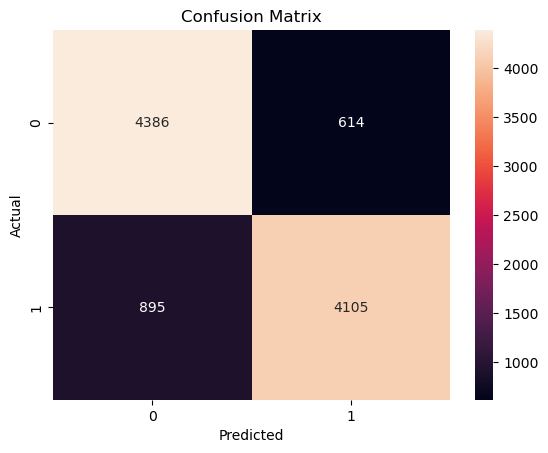

In [79]:
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Test Our Own Movie Reviews

In [80]:
new_review = ["This movie was absolutely amazing. The acting was excellent and I really enjoyed every scene."]

In [81]:
new_review_clean = [clean_text(review) for review in new_review]
print(new_review_clean)

['this movie was absolutely amazing the acting was excellent and i really enjoyed every scene']


In [82]:
new_review_vector = vectorizer.transform(new_review_clean)

In [83]:
prediction = model.predict(new_review_vector)
print(prediction)

[1]


In [84]:
if prediction[0] == 1:
    print("🎬 Sentiment: POSITIVE")
else:
    print("🎬 Sentiment: NEGATIVE")

🎬 Sentiment: POSITIVE


# Test a Negative Review

In [85]:
new_review = ["This movie was terrible and boring. The story was very disappointing and the acting was poor."]

In [86]:
new_review_clean = [clean_text(review) for review in new_review]
new_review_vector = vectorizer.transform(new_review_clean)
prediction = model.predict(new_review_vector)
if prediction[0] == 1:
    print("🎬 Sentiment: POSITIVE")
else:
    print("🎬 Sentiment: NEGATIVE")

🎬 Sentiment: NEGATIVE


In [87]:
def predict_sentiment(review):
    review_clean = clean_text(review)
    review_vector = vectorizer.transform([review_clean])
    prediction = model.predict(review_vector)

    if prediction[0] == 1:
        return "Positive"
    else:
        return "Negative"

In [88]:
print(predict_sentiment("The movie was fantastic and I loved it!"))

Positive


In [89]:
print(predict_sentiment("The movie was extremely boring and disappointing."))

Negative


# Train Logistic Regression

In [90]:
from sklearn.linear_model import LogisticRegression
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(x_train_bow, y_train)
print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [91]:
y_pred_lr = logistic_model.predict(x_test_bow)
print(y_pred_lr[:10])

[0 1 1 0 0 0 0 0 1 0]


In [92]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)
print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", accuracy_lr)
print("Precision:", precision_lr)
print("Recall   :", recall_lr)
print("F1 Score :", f1_lr)

Logistic Regression Results
---------------------------
Accuracy : 0.8902
Precision: 0.8892657621707901
Recall   : 0.8914
F1 Score : 0.890331602077507


# Compare Both Models

In [93]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Naive Bayes": [accuracy, precision, recall, f1],
    "Logistic Regression": [
        accuracy_lr,
        precision_lr,
        recall_lr,
        f1_lr
    ]
})

comparison

,Metric,Naive Bayes,Logistic Regression
0,Accuracy,0.849100,0.890200
1,Precision,0.869888,0.889266
2,Recall,0.821000,0.891400
3,F1 Score,0.844737,0.890332


In [94]:
if accuracy_lr > accuracy:
    print("Best Model: Logistic Regression")
else:
    print("Best Model: Multinomial Naive Bayes")

Best Model: Logistic Regression


In [95]:
%pip install gradio

Note: you may need to restart the kernel to use updated packages.


In [96]:
import gradio as gr

In [104]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

In [105]:
def predict_sentiment(review):
    try:
        review_clean = clean_text(review)
        review_vector = vectorizer.transform([review_clean])
        prediction = model.predict(review_vector)

        if prediction[0] == 1:
            return "😊 Positive Review"
        else:
            return "😞 Negative Review"

    except Exception as e:
        return f"Error: {str(e)}"

In [106]:
print(predict_sentiment("This movie was amazing and I loved it!"))

😊 Positive Review


In [108]:
print(predict_sentiment("This movie was boring and disappointing."))

😞 Negative Review


In [109]:
demo = gr.Interface(
    fn=predict_sentiment,
    inputs=gr.Textbox(
        lines=6,
        label="Movie Review",
        placeholder="Enter your movie review here..."
    ),
    outputs=gr.Textbox(label="Sentiment Prediction"),
    title="🎬 Movie Review Sentiment Analysis",
    description="Enter a movie review and the NLP model will predict whether it is Positive or Negative.",
    examples=[
        ["This movie was amazing and the acting was excellent!"],
        ["The movie was boring and disappointing."],
        ["I really enjoyed this film. The story was fantastic."]
    ]
)

In [110]:
demo.launch()

* Running on local URL:  http://127.0.0.1:7865
* To create a public link, set `share=True` in `launch()`.


Created dataset file at: .gradio\flagged\dataset1.csv
